# Batch Key Comparison

- **Purpose:** Compare scVI integrations trained with different batch keys and inspect their effect on tumor structure.
- **Inputs:** `data/processed/preprocessed_tumor.h5ad`; saved scVI checkpoints from the original experiments.
- **Outputs:** Plots and tables shown in the notebook; no artifacts are saved.
- **Status:** Exploratory.
- **Note:** The saved checkpoints are not tracked, so the notebook is a record of the batch-key decision rather than a rerunnable pipeline step.


In [1]:
import pandas as pd
import numpy as np
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns

import scvi
import os
import re

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import pairwise_distances
from scipy.spatial.distance import cdist

from scib_metrics.benchmark import Benchmarker, BioConservation, BatchCorrection
from rich import pretty
pretty.install()

In [2]:
import torch 
torch.set_float32_matmul_precision("high")

seed = 0
scvi.settings.seed = seed
torch.manual_seed(seed)
np.random.seed(seed)

Seed set to 0


In [3]:
DATA_DIR = os.path.join("..", "..", "data")
PROCESSED_DIR = os.path.join(DATA_DIR, "processed")
MODELS_DIR = os.path.join("..", "..", "models")

tumor_path = os.path.join(PROCESSED_DIR, "preprocessed_tumor.h5ad")
cell_line_path = os.path.join(PROCESSED_DIR, "preprocessed_cell_line.h5ad")

In [4]:
adata_tumor = ad.read_h5ad(tumor_path)

In [5]:
adata_tumor


AnnData object with n_obs × n_vars = 108131 × 28617
    obs: 'cell_id', 'donor_id', 'biosample_id', 'mmr_status', 'chemistry', 'batch', 'label', 'cell_type', 'dataset', 'mlh1_status', 'sex', 'tissue_site', 'pathological_stage', 'tumor_grade', 'c_value'
    var: 'gene_symbol', 'gene_id'

In [6]:
def qc_metrics(adata):
    adata.var["mt"] = adata.var_names.str.startswith(("MT-"))
    adata.var["ribo"] = adata.var_names.str.startswith(("RPL", "RPS"))
    # adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")
    # adata.var["ig"] = adata.var_names.str.startswith(("IG"))
    # adata.var["hla"] = adata.var_names.str.startswith(("HLA"))
    # adata.var["hsp"] = adata.var_names.str.startswith(("HSP"))
    # adata.var["malat1"] = adata.var_names.str.startswith("MALAT1")
    # adata.var["xist"] = adata.var_names.str.startswith("XIST")

    sc.pp.calculate_qc_metrics(
        adata, qc_vars=["mt", "ribo"],
        percent_top=None,
        log1p=True, inplace=True
    )
    return adata

def log_normal(adata):
    adata.layers["counts"] = adata.X.copy()
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    adata.raw = adata
    return adata

adata_tumor = qc_metrics(adata_tumor)
adata_tumor = log_normal(adata_tumor)

In [7]:
sc.tl.pca(adata_tumor)
sc.pp.neighbors(adata_tumor, use_rep="X_pca")
sc.tl.umap(adata_tumor)

# Batch effects overview
- We have the existing malignant epithelial cell subtype labels from Pelka et al.
- We want to FULLY integrate ALL epithelial cells from their study. Even tho we know that some donors have biological differences like somatic mutations and CNV.
- We want to get a shared latent space of the malignant epithelial cells: We want to remove technical artefacts but biology/donor is confounded with the technical variation. Deep confounding due to each donor being processed separately.
- We can check if we remove the technical variation by checking batch mixing and biological conservation: Cells of the same type from different donors should be close to each other while cells of different types stay separate: scIB (or quick visually as here)


What we can see here in these UNINTEGRATED UMAP plots:
- We obtain these donor/batch clusters: the cells within one cluster are from the same donor/batch
- The label is not mixed between donors due to the donor/batch clusters
- The mixing in the middle is mostly due to the "low quality" cells as i would name them. So v2 cells with low total_counts and low genes expressed -> mostly just stem/ta-like cells so still biologically relevant and i am relucant to remove them as one would do in the iterative approach.

In [7]:
adata_tumor.obs["enrichment_id"] = adata_tumor.obs["biosample_id"].str.split("_").str[4]

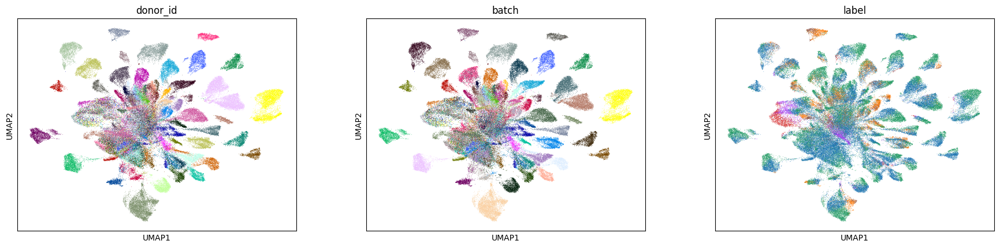

In [9]:
sc.pl.umap(
    adata_tumor, color=["donor_id", "batch", "label"], legend_loc=None
)

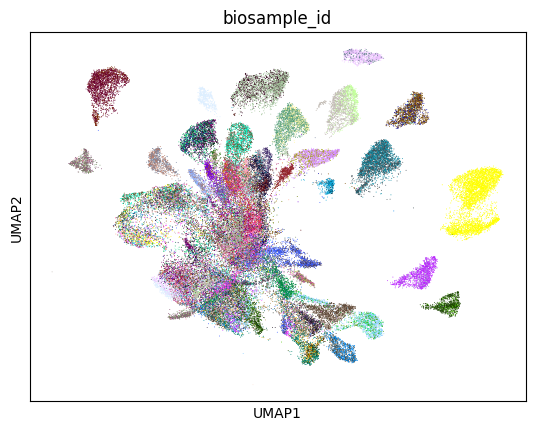

In [10]:
adata_subset = adata_tumor[adata_tumor.obs.chemistry == "v2"].copy()
adata_subset.obs.biosample_id = adata_subset.obs.biosample_id.cat.remove_unused_categories()
adata_subset = adata_subset[np.random.permutation(adata_subset.n_obs)].copy()

sc.pl.umap(adata_subset, color=["biosample_id"], legend_loc=None)

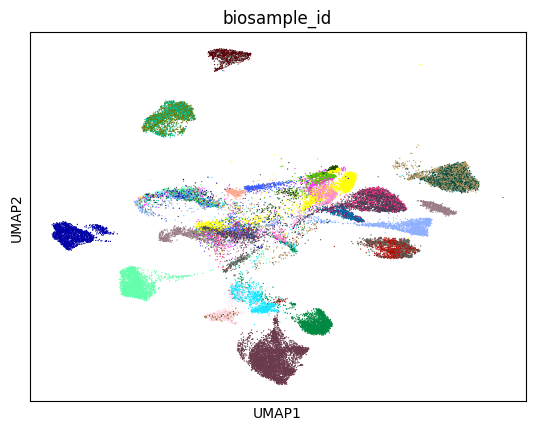

In [11]:
adata_subset = adata_tumor[adata_tumor.obs.chemistry == "v3"].copy()
adata_subset.obs.biosample_id = adata_subset.obs.biosample_id.cat.remove_unused_categories()
adata_subset = adata_subset[np.random.permutation(adata_subset.n_obs)].copy()

sc.pl.umap(adata_subset, color=["biosample_id"], legend_loc=None)

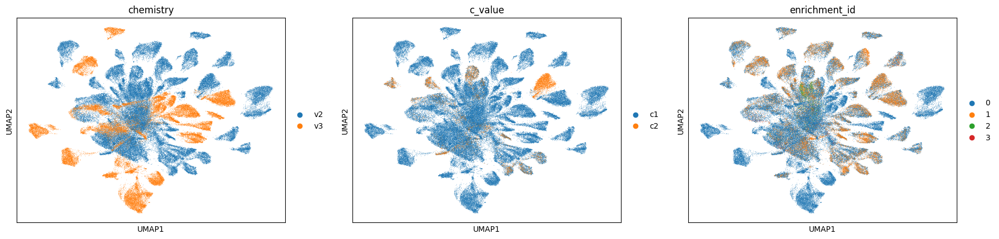

In [12]:
sc.pl.umap(adata_tumor, color=["chemistry", "c_value", "enrichment_id"])

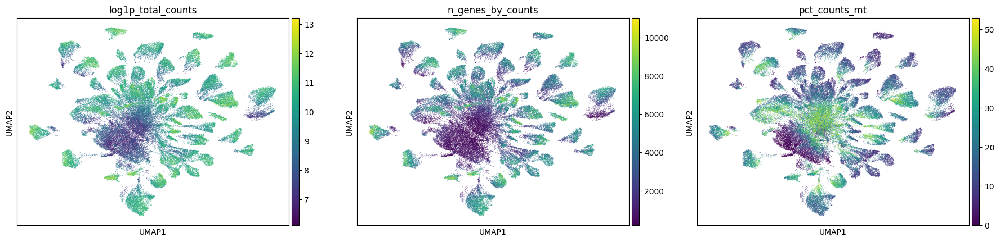

In [13]:
sc.pl.umap(adata_tumor, color=["log1p_total_counts", "n_genes_by_counts", "pct_counts_mt"])

# Check c_value's effect for mixing
The c_value is not described in the paper/excel from the SCP1162/GSE178341 dataset. 
Is the c_value which is extracted from the biosample_id an indicator for a 10x channel?

- I assumed: each donor was sampled separately
- I check: Is each biosample a separate 10x run? -> If yes, we would expect separation between the c_values conditioned on each donor

All plotted donors with both c_values c1 and c2 do not show any type of technical artefacts. The only exception being the donor C162 due to the c_value that is confounded with the chemistry version. Obviously the batch effects in C162 are a result of the different library chemistry. This confirms that the c_value does not compromise a single 10x channel or controller. 

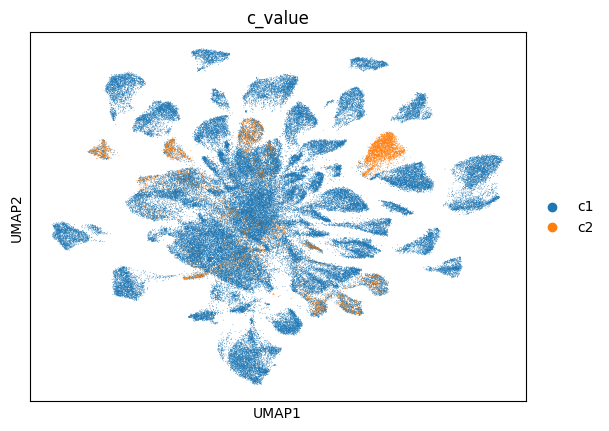

In [14]:
sc.pl.umap(adata_tumor, color="c_value")

In [15]:
def donor_biosample_visualization(donor: str):
    adata_subset = adata_tumor[adata_tumor.obs.donor_id==donor].copy()
    adata_subset.obs.biosample_id = adata_subset.obs.biosample_id.cat.remove_unused_categories()
    adata_subset = adata_subset[np.random.permutation(adata_subset.n_obs)].copy()
    
    sc.pl.umap(adata_subset, color=["label", "batch", "biosample_id"])    
    sc.pl.umap(adata_subset, color=["log1p_total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"])

    sc.pl.umap(adata_tumor, mask_obs=(adata_tumor.obs.donor_id==donor), color=["label"])

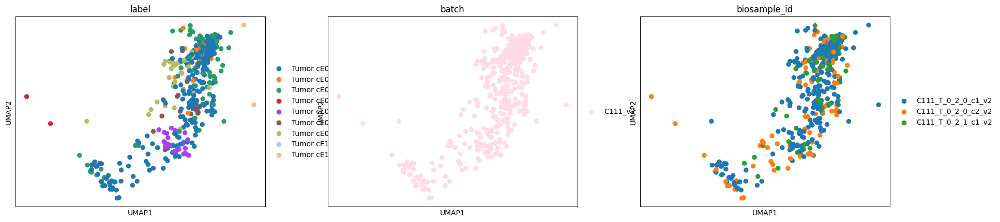

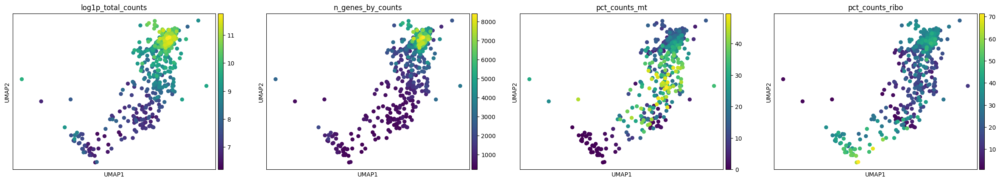

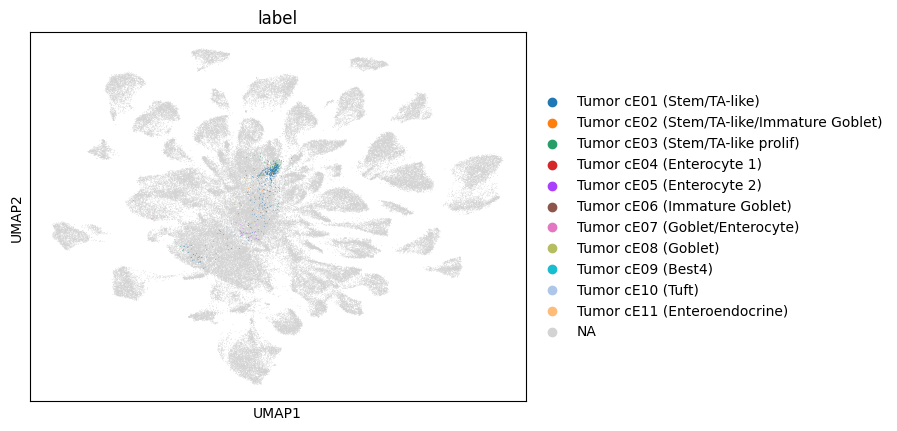

In [16]:
donor_biosample_visualization("C111")

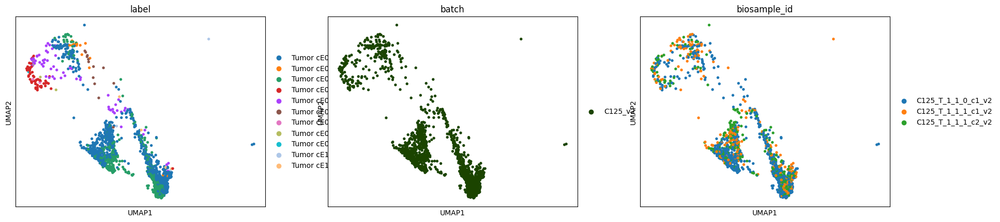

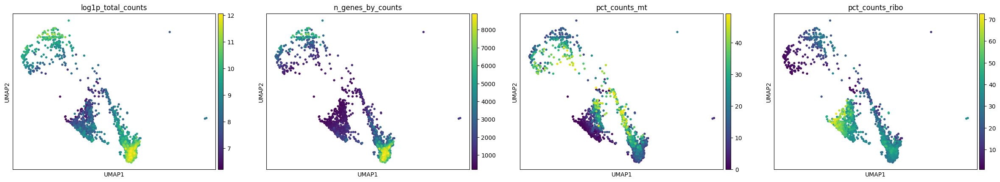

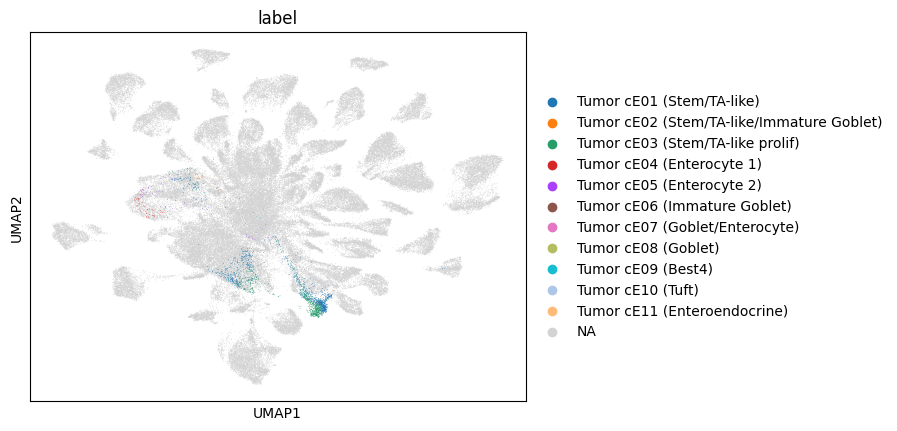

In [17]:
donor_biosample_visualization("C125")

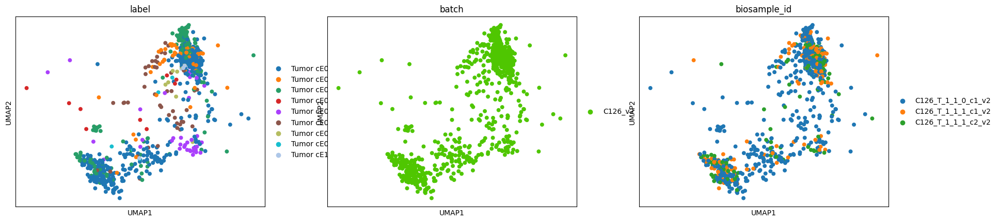

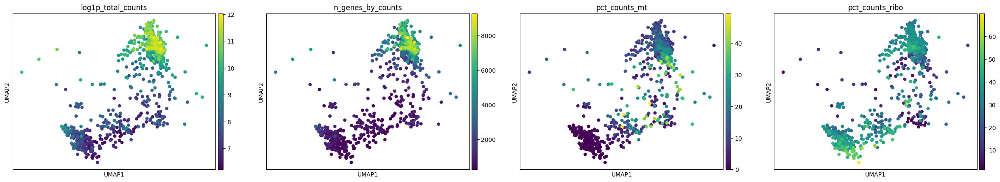

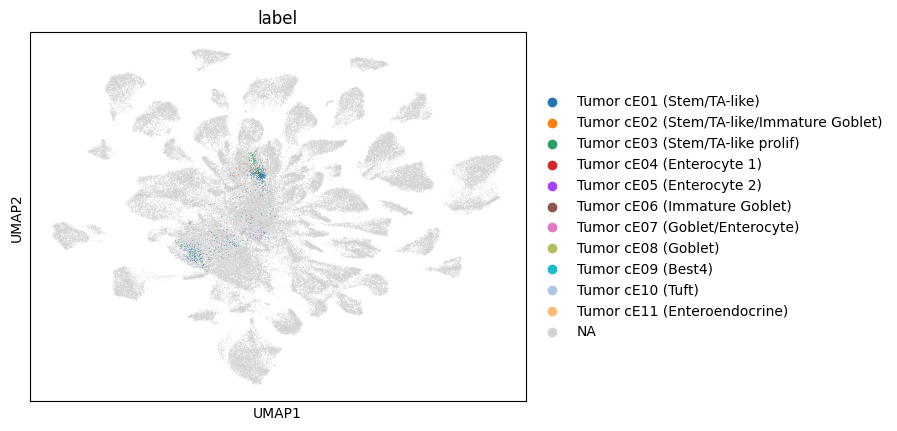

In [18]:
donor_biosample_visualization("C126")

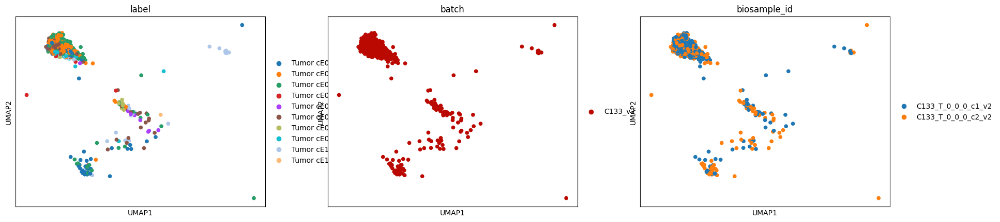

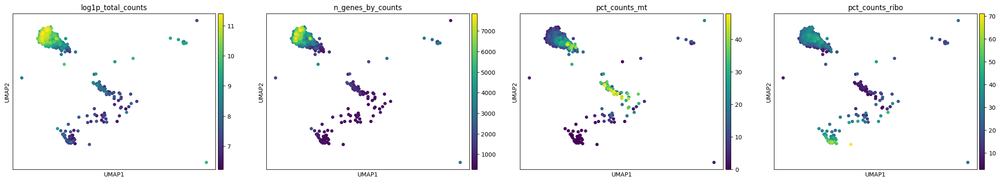

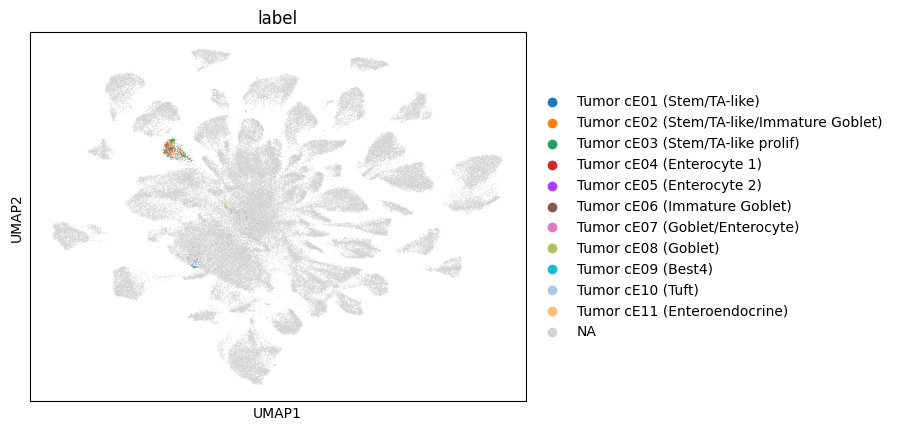

In [19]:
donor_biosample_visualization("C133")

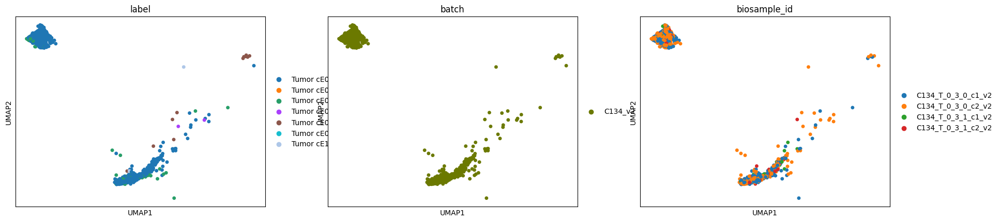

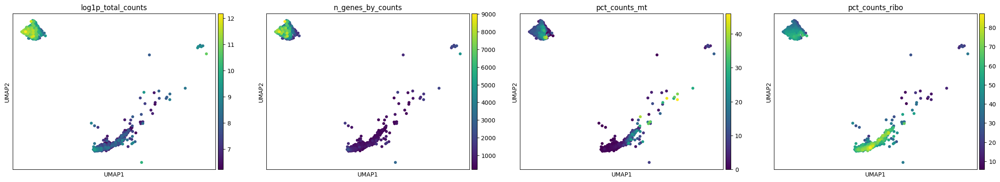

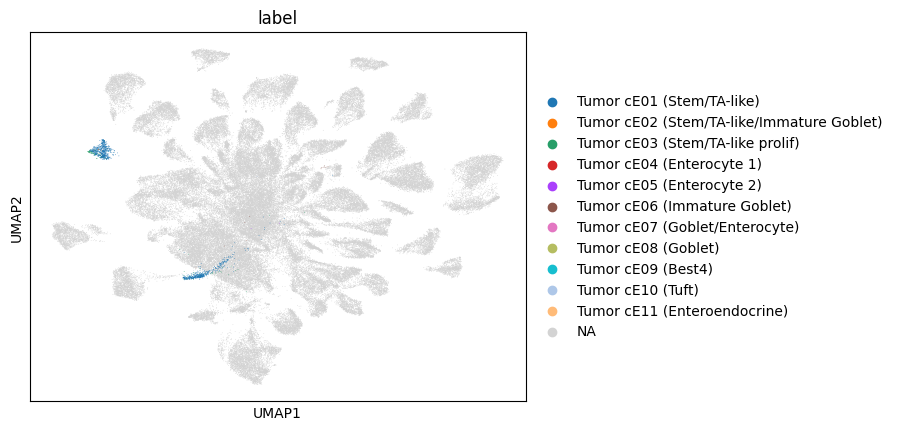

In [20]:
donor_biosample_visualization("C134")

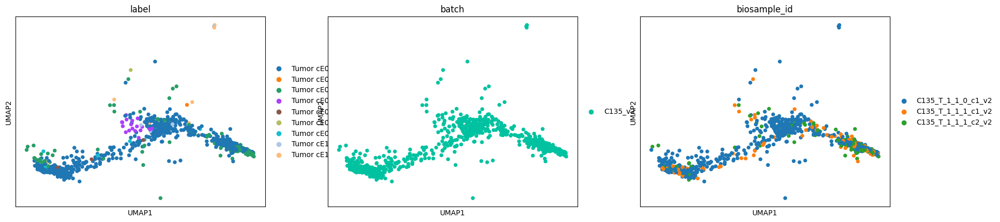

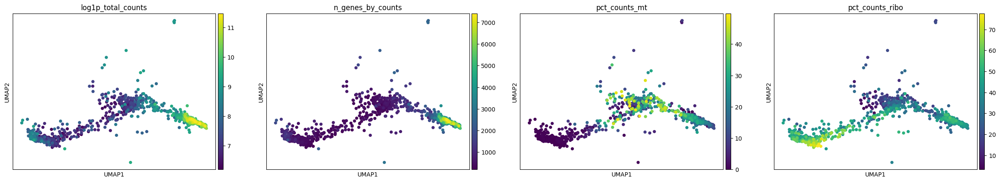

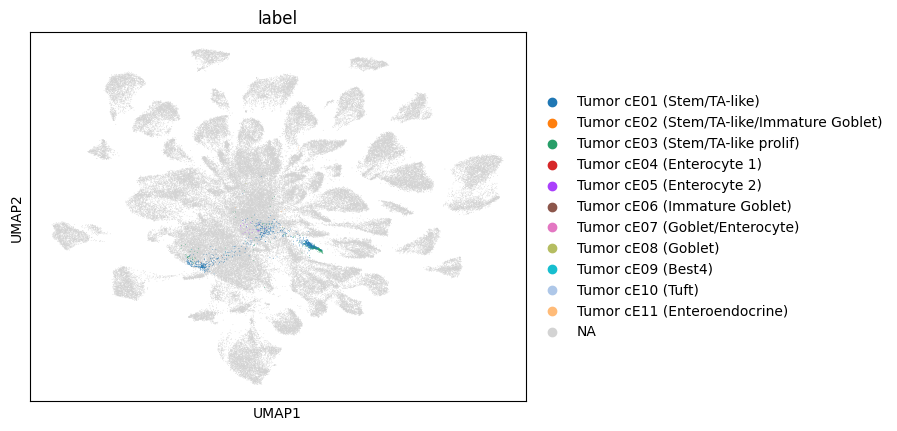

In [21]:
donor_biosample_visualization("C135")

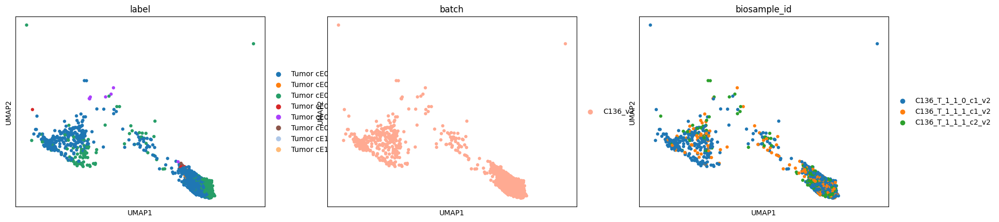

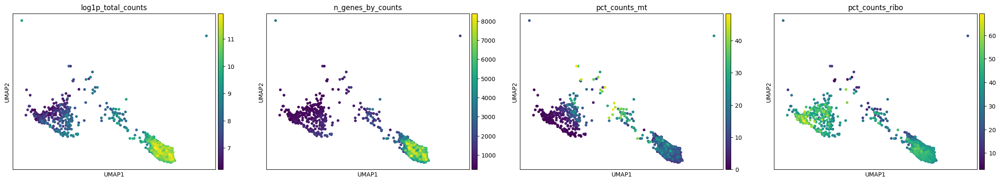

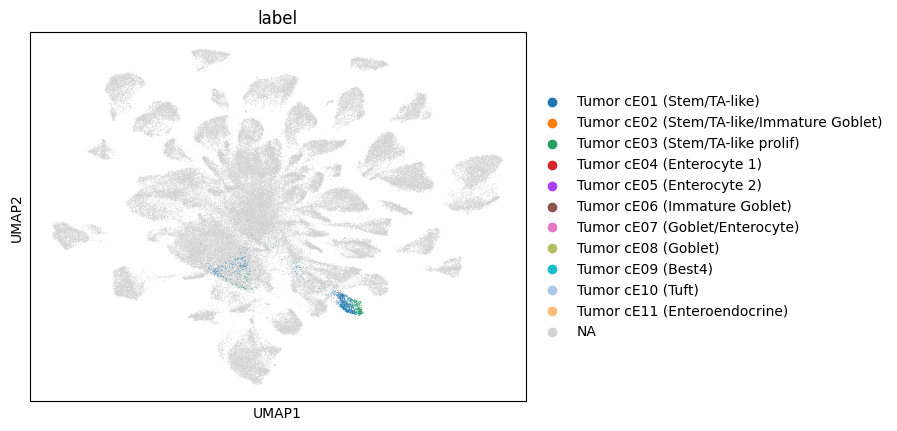

In [22]:
donor_biosample_visualization("C136")

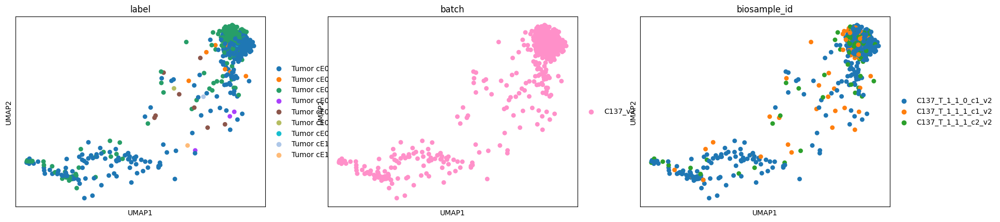

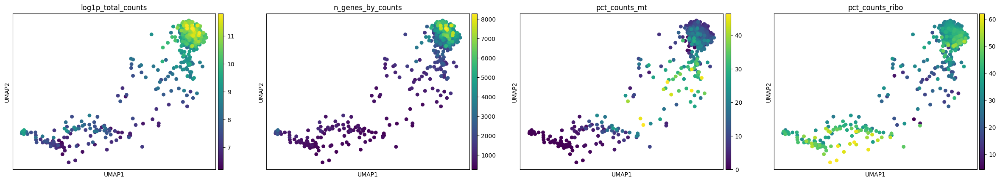

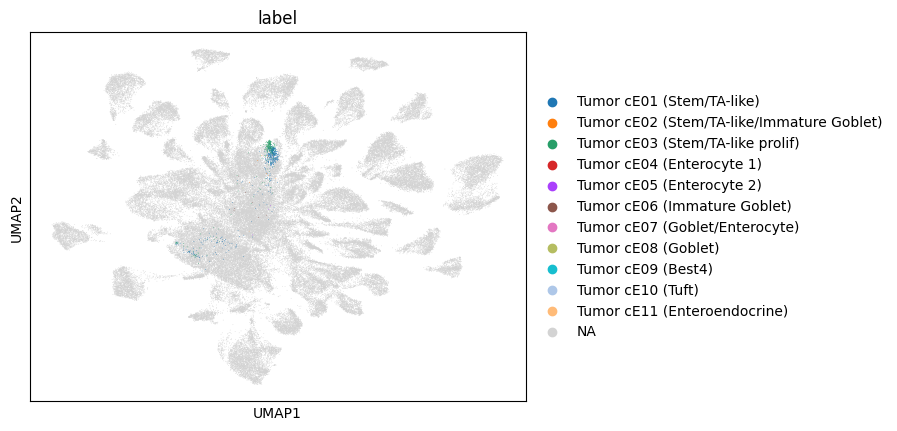

In [23]:
donor_biosample_visualization("C137")

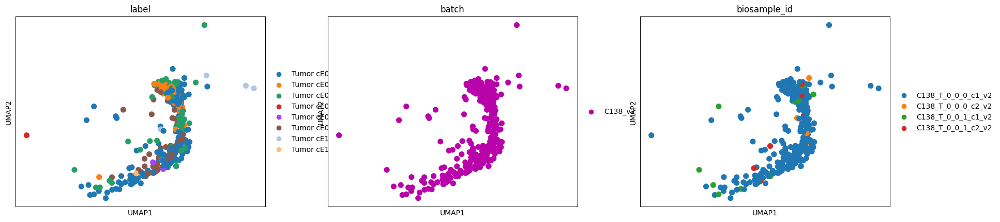

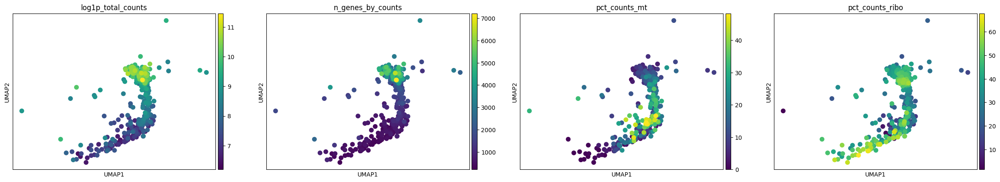

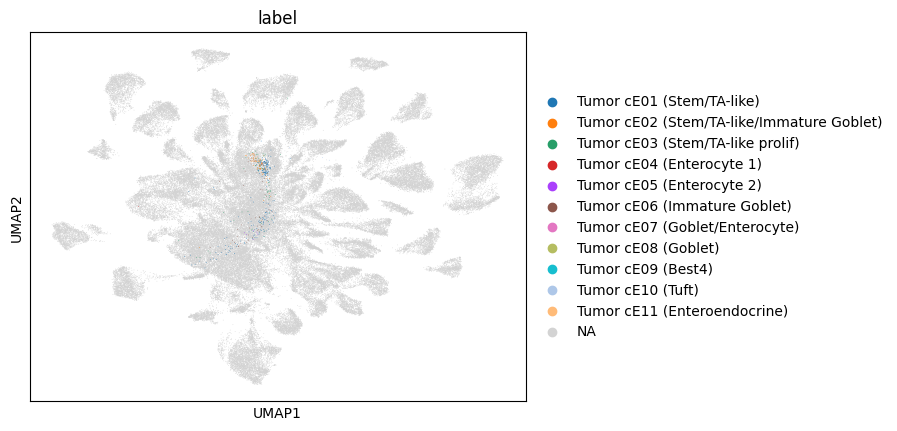

In [24]:
donor_biosample_visualization("C138")

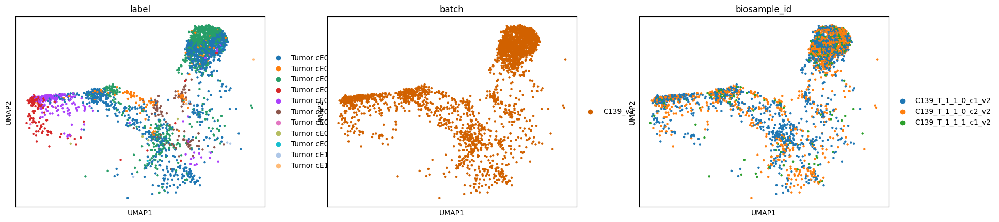

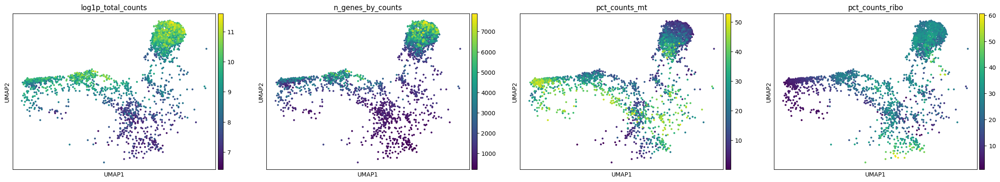

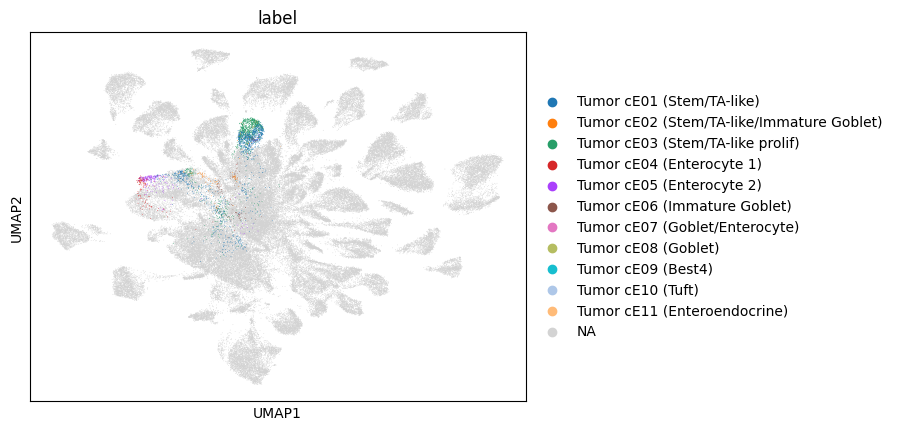

In [25]:
donor_biosample_visualization("C139")

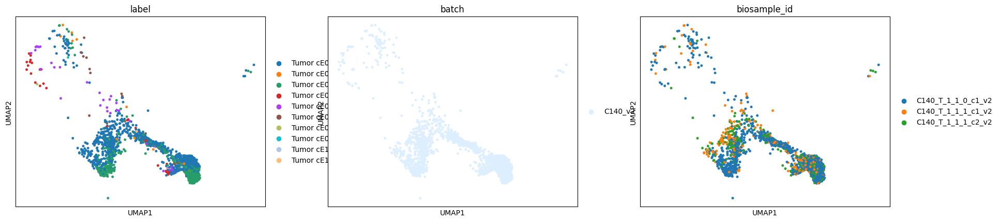

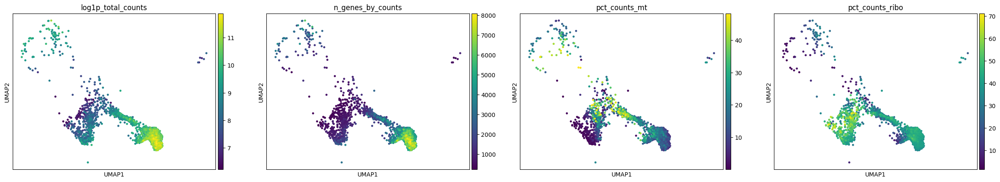

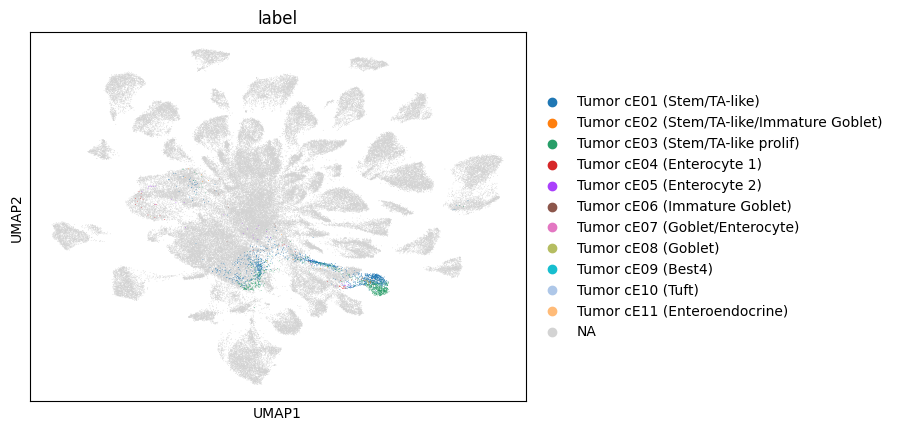

In [26]:
donor_biosample_visualization("C140")

# Special case C162: c1/c2 and v2/v3 
This PCA UMAP describes the differences pretty well. We have the differnces between donors from somatic mutations, CNA etc. which are pretty big and make up the dominant part of variation between malignant epithelial cells.

We want to integrate our tumor data into a shared latent space, where donors cluster by shared transcriptional programs. Therefore, we need to integrate using at least a donor_id level batch_key. This allows us to compare epithelial tumor cell states between the individuals (while later using scANVI with the common transcriptional states across donors that were identified ACROSS donors). However, we must consider that batch_key and donor are confounded. We will overcorrect by default as scVI tries to erase the differences between the batches which inclues the biological differences between the patient tumors.

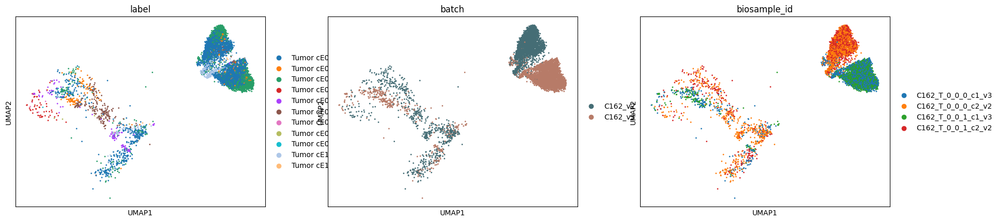

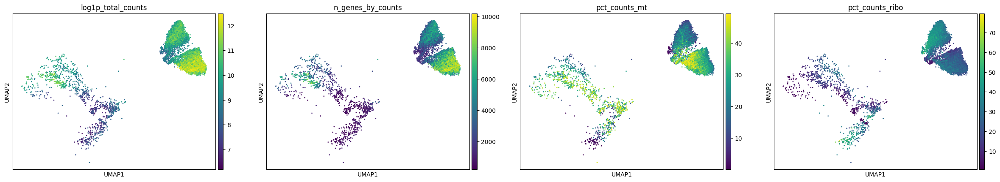

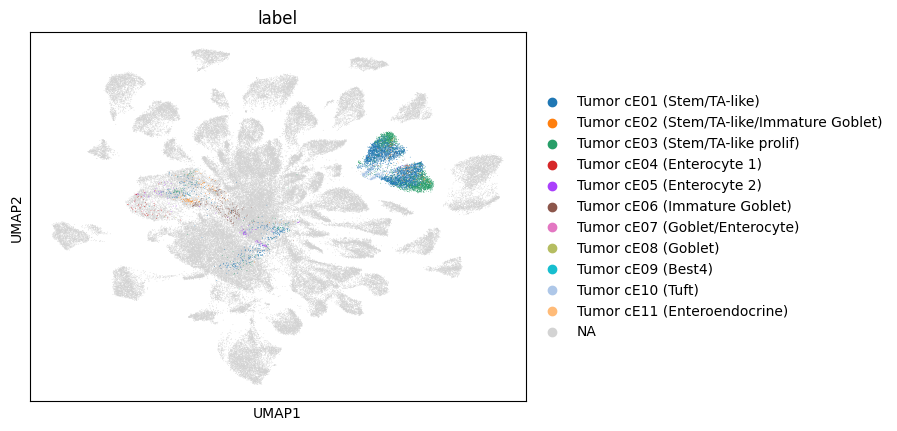

In [27]:
donor_biosample_visualization("C162")

# TA/TB lesion specific variation
The donor C130 and C171 had two lesions of their tumor sequenced. 

The C130 PCA UMAP shows: 
- TA/TB samples do NOT separate in the unintegrated space -> same donor, same transcriptional profile. I do not know if different sequencing runs but it still shows that the two samples are really similar (i guess same 10x run as different we would have more separation: Figure 3 in Luecken & Theis 2019 sc-best-practices. There we can clearly see the separation of donors even if similar transcriptional profile)
- TA/TB samples carry the same malignant transcriptional profiles.


The C171 PCA UMAP shows:
- We have nearly complete separation between the samples: same donor, different transcriptional profile: Again, we do not know if different 10x channels (i guess not) but the separation might be due to subclonal populations.
- This is a biological finding (I think) and should not be removed as a batch effect -> TA/TB samples in different batches would correct and remove this heterogeneity. But

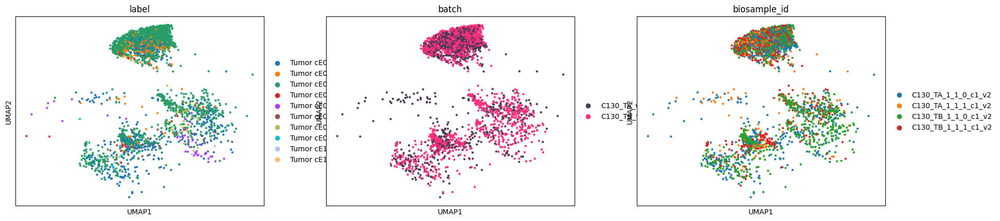

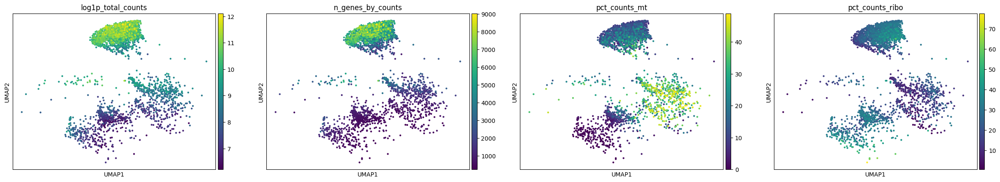

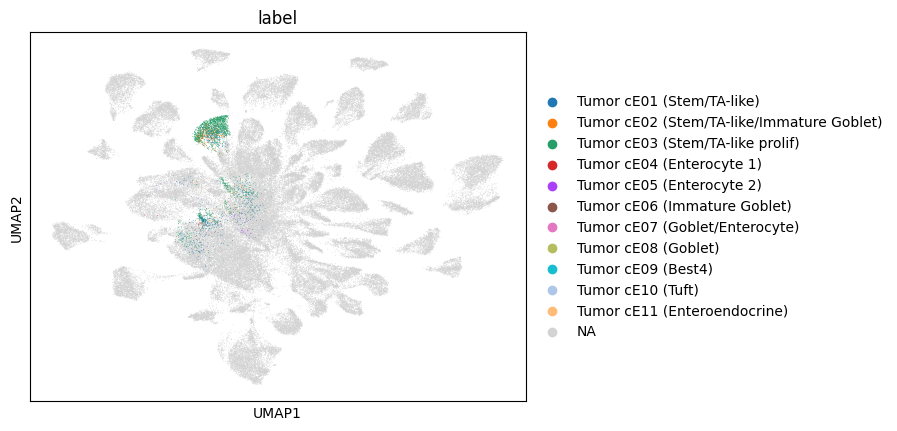

In [28]:
donor_biosample_visualization("C130")

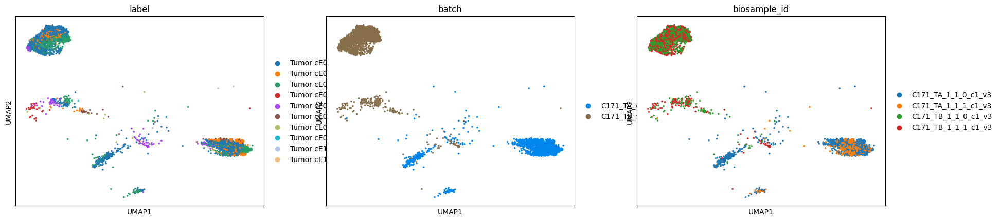

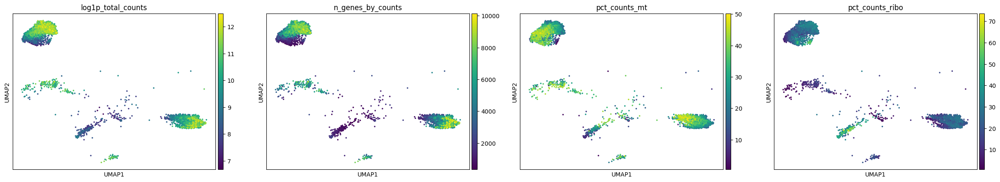

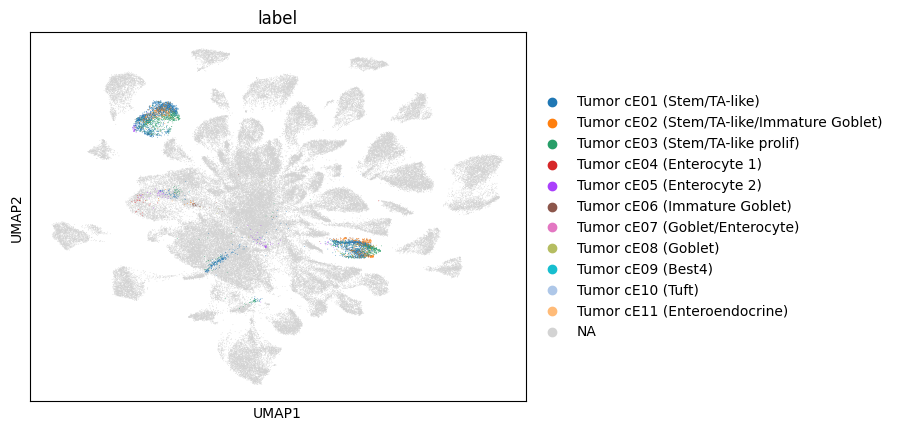

In [29]:
donor_biosample_visualization("C171")

# Integration via scVI


HPO: 

num_hvg = [3000,5000,10000]
n_latent = [10,25,50]
n_hidden = [128,256]
n_layers = [1,2,3]
encode_covariates = [True,False]
dispersion = [gene, gene-batch]
n_samples_per_label = [None, 100]
 

fixed parameter:

batch_key = donor_sample_chemistry oder pool
use_observed_lib_size = True
deeply_inject_covariates = True
gene_likelihood = zinb
early_stopping = True mit stratified 90/10 train-val-split per batch
batch_size = 256
n_epochs_kl_warmup = [50 bei scVI und scANVI und 20 bei scArches]

In [7]:
def visualizations(adata, scvi):
    latent_key = "X_scVI"
    adata.obsm[latent_key] = scvi.get_latent_representation(adata)
    sc.pp.neighbors(adata, use_rep=latent_key)
    sc.tl.umap(adata)
    
    sc.pl.umap(adata, color=["label", "batch"])
    sc.pl.umap(adata, color=["log1p_total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"])

In [8]:
# model paras
n_layer = 3
n_hidden = 256
n_latent = 25
num_hvg = 5000

# training paras
batch_size = 256
learning_rate = 2e-3
early_stopping_patience = 15
n_epochs_kl_warmup = 50


# VAE -> scvi.model **kwargs
deeply_inject_covariates = True
encode_covariates = False

In [9]:
# currently do not have a donor_chem key
adata_tumor.obs["donor_chem"] = adata_tumor.obs["donor_id"].astype(str) + "_" + adata_tumor.obs["chemistry"].astype(str)

## None

In [10]:
adata_none = adata_tumor.copy()

sc.pp.highly_variable_genes(
    adata_none,
    n_top_genes=num_hvg,
    subset=True,
    layer="counts",
    flavor="seurat_v3",
    batch_key=None
)

In [11]:
if True: 
    scvi_none = scvi.model.SCVI.load("scvi_log/2026-08-02_21-36-42_elbo_validation/epoch=387-step=147828-elbo_validation=1971.58154296875",
                                     adata=adata_none)
else: 
    scvi.model.SCVI.setup_anndata(
        adata_none,
        layer="counts",
        batch_key=None
    )

    scvi_none = scvi.model.SCVI(
        adata_none,
        # model paras
        n_layers = n_layer,
        n_hidden = n_hidden,
        n_latent = n_latent,
        # VAE paras
        encode_covariates=encode_covariates,
        deeply_inject_covariates=deeply_inject_covariates
    )

    scvi_none.train(
        batch_size=256,
        early_stopping=True, max_epochs=400,
        callbacks=[
            scvi.train.SaveCheckpoint(
                monitor="elbo_validation", load_best_on_end=True
            )
        ],
        datasplitter_kwargs={"num_workers":3},
        plan_config={"n_epochs_kl_warmup":50},
        
    )

INFO     File                                                                                                      
         scvi_log/2026-08-02_21-36-42_elbo_validation/epoch=387-step=147828-elbo_validation=1971.58154296875/model.
         pt already downloaded                                                                                     


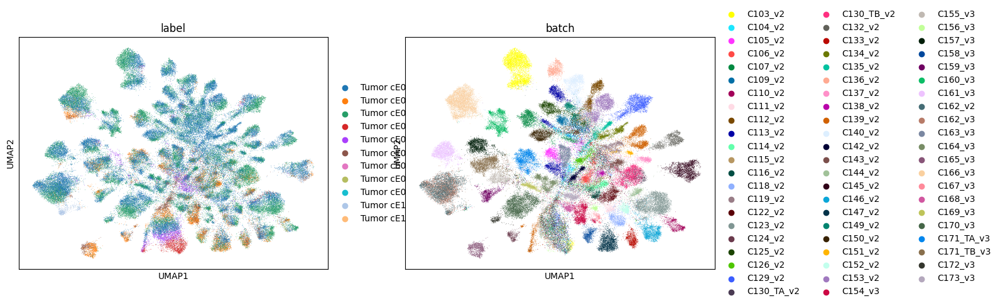

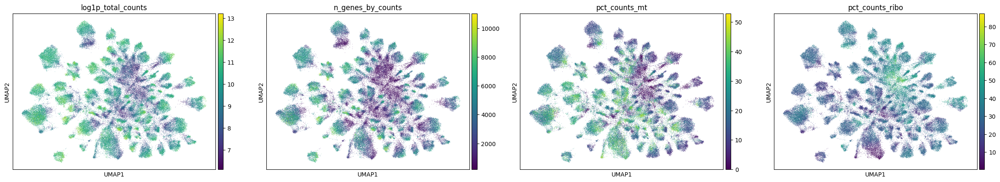

In [12]:
visualizations(adata_none, scvi_none)

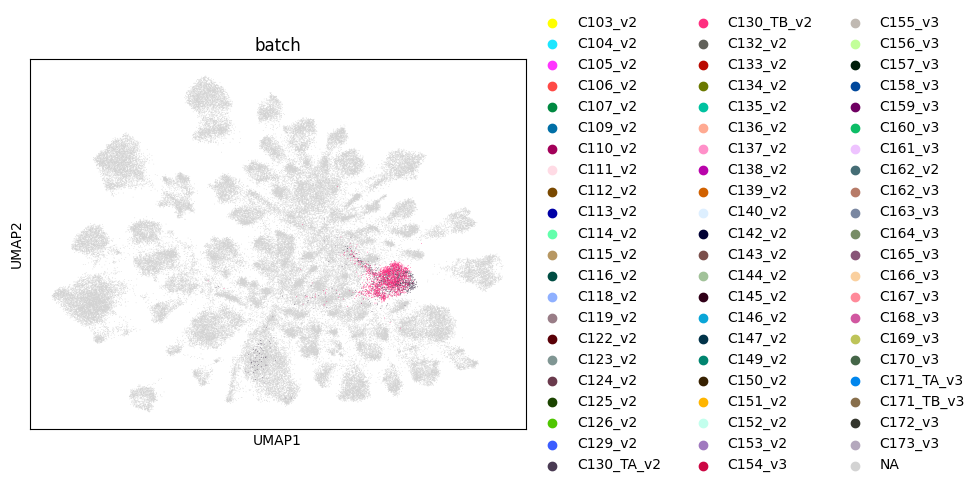

In [13]:
sc.pl.umap(adata_none, mask_obs=adata_none.obs.donor_id=="C130", color="batch")

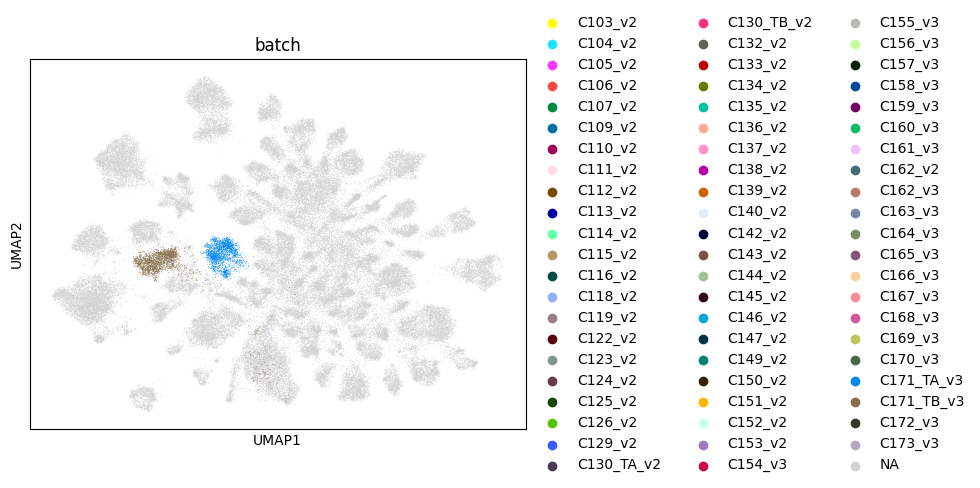

In [14]:
sc.pl.umap(adata_none, mask_obs=adata_none.obs.donor_id=="C171", color="batch")

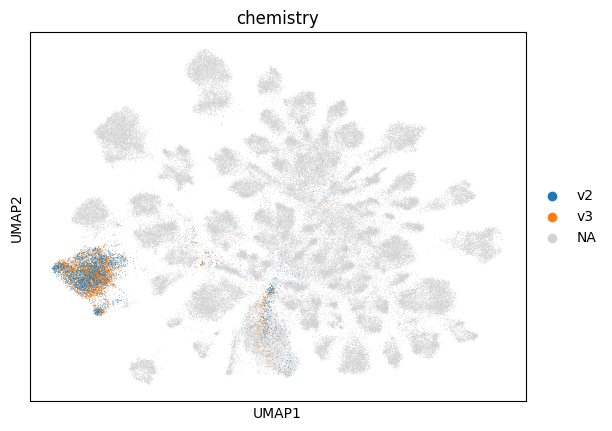

In [23]:
sc.pl.umap(adata_none, mask_obs=adata_none.obs.donor_id=="C162", color="chemistry")

scVI is able to correc the v2/v3 differences without a batch key. 

In [41]:
del adata_none, scvi_none

## Chem

In [15]:
adata_chem = adata_tumor.copy()

sc.pp.highly_variable_genes(
    adata_chem,
    n_top_genes=num_hvg,
    subset=True,
    layer="counts",
    flavor="seurat_v3",
    batch_key="chemistry"
)

In [16]:
if True: 
    scvi_chem = scvi.model.SCVI.load("scvi_log/2026-08-03_08-06-19_elbo_validation/epoch=399-step=152400-elbo_validation=1949.357421875",
                                     adata=adata_chem)
else: 
    scvi.model.SCVI.setup_anndata(
        adata_chem,
        layer="counts",
        batch_key="chemistry"
    )

    scvi_chem = scvi.model.SCVI(
        adata_chem,
        # model paras
        n_layers = n_layer,
        n_hidden = n_hidden,
        n_latent = n_latent,
        # VAE paras
        encode_covariates=encode_covariates,
        deeply_inject_covariates=deeply_inject_covariates
    )

    scvi_chem.train(
        batch_size=256,
        early_stopping=True, max_epochs=400,
        callbacks=[
            scvi.train.SaveCheckpoint(
                monitor="elbo_validation", load_best_on_end=True
            )
        ],
        datasplitter_kwargs={"num_workers":3},
        plan_config={"n_epochs_kl_warmup":50},
    )

INFO     File                                                                                                      
         scvi_log/2026-08-03_08-06-19_elbo_validation/epoch=399-step=152400-elbo_validation=1949.357421875/model.pt
         already downloaded                                                                                        


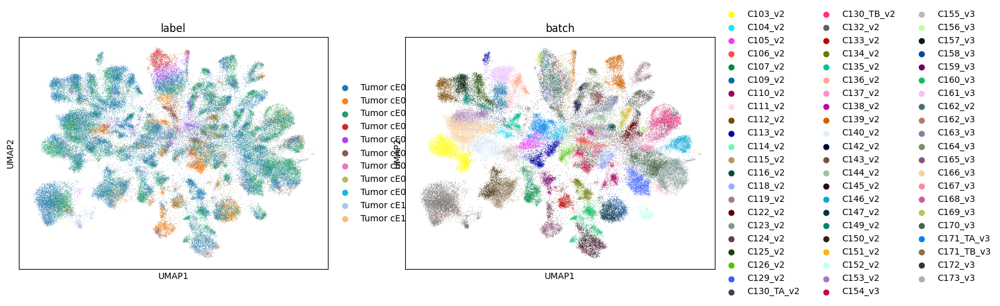

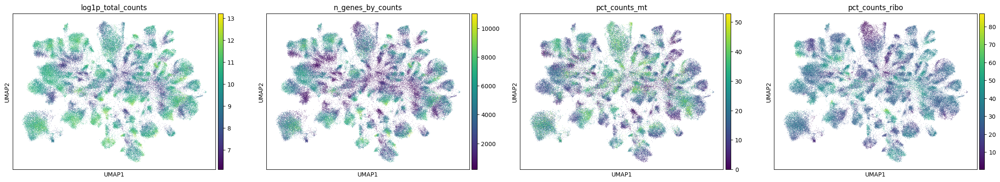

In [17]:
visualizations(adata_chem, scvi_chem)

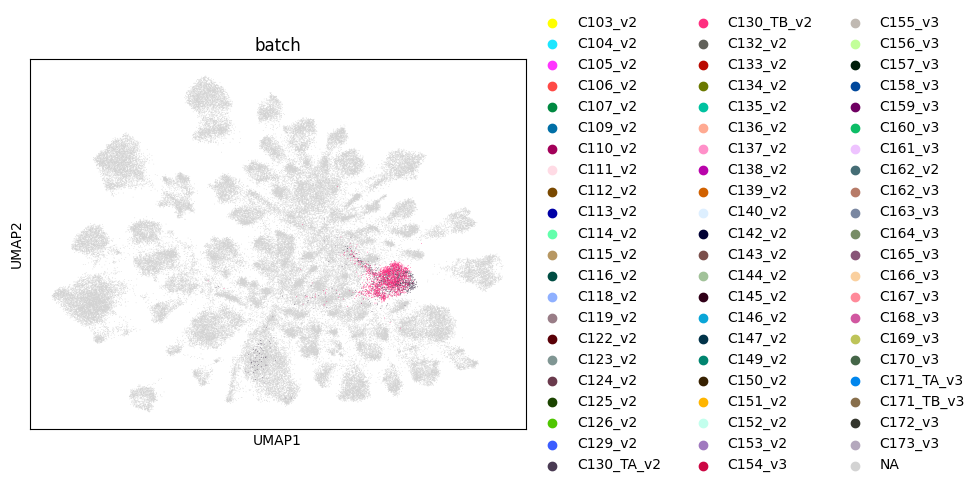

In [18]:
sc.pl.umap(adata_none, mask_obs=adata_none.obs.donor_id=="C130", color="batch")

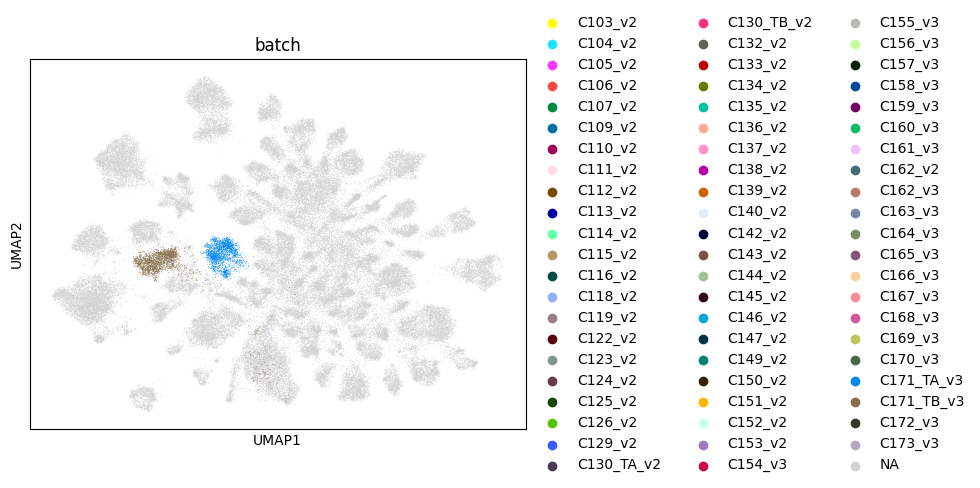

In [19]:
sc.pl.umap(adata_none, mask_obs=adata_none.obs.donor_id=="C171", color="batch")

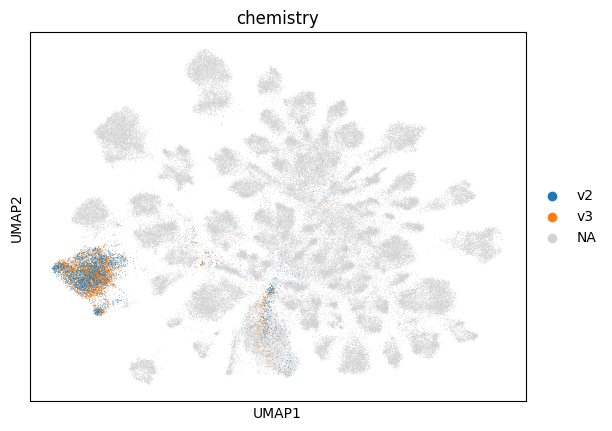

In [20]:
sc.pl.umap(adata_none, mask_obs=adata_none.obs.donor_id=="C162", color="chemistry")

In [40]:
del adata_chem, scvi_chem

## Donor

In [10]:
adata_donor = adata_tumor.copy()

sc.pp.highly_variable_genes(
    adata_donor,
    n_top_genes=num_hvg,
    subset=True,
    layer="counts",
    flavor="seurat_v3",
    batch_key="donor_id"
)

In [11]:
if True: 
    scvi_donor = scvi.model.SCVI.load("scvi_log/2026-08-03_09-03-33_elbo_validation/epoch=259-step=99060-elbo_validation=2004.51318359375",
                                     adata=adata_donor)
else: 
    scvi.model.SCVI.setup_anndata(
        adata_donor,
        layer="counts",
        batch_key="donor_id"
    )

    scvi_donor = scvi.model.SCVI(
        adata_donor,
        # model paras
        n_layers = n_layer,
        n_hidden = n_hidden,
        n_latent = n_latent,
        # VAE paras
        encode_covariates=encode_covariates,
        deeply_inject_covariates=deeply_inject_covariates
    )

    scvi_donor.train(
        batch_size=256,
        early_stopping=True, max_epochs=400,
        callbacks=[
            scvi.train.SaveCheckpoint(
                monitor="elbo_validation", load_best_on_end=True
            )
        ],
        datasplitter_kwargs={"num_workers":3},
        plan_config={"n_epochs_kl_warmup":50},
    )

INFO     File                                                                                                      
         scvi_log/2026-08-03_09-03-33_elbo_validation/epoch=259-step=99060-elbo_validation=2004.51318359375/model.p
         t already downloaded                                                                                      


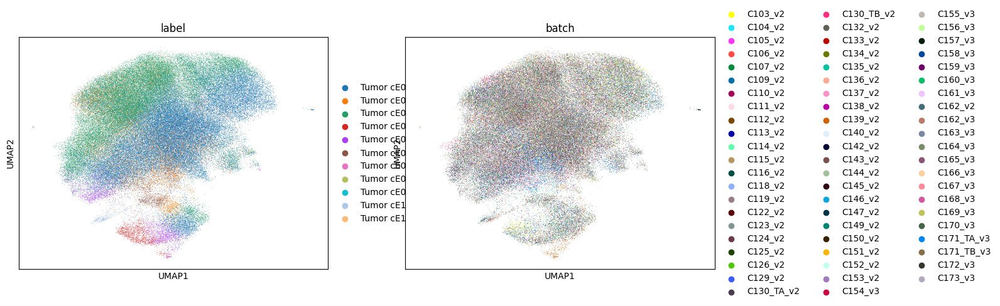

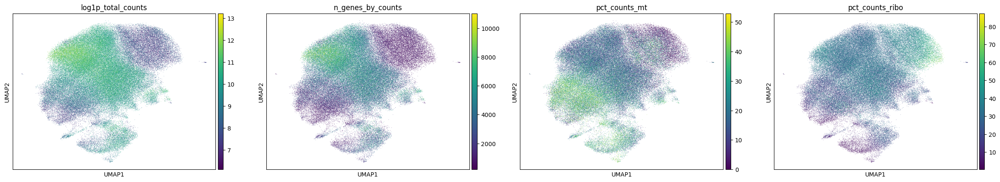

In [12]:
visualizations(adata_donor, scvi_donor)

In [45]:
del adata_donor, scvi_donor

## Donor_chem

In [33]:
adata_donor_chem = adata_tumor.copy()

sc.pp.highly_variable_genes(
    adata_donor_chem,
    n_top_genes=num_hvg,
    subset=True,
    layer="counts",
    flavor="seurat_v3",
    batch_key="donor_chem"
)

In [34]:
if True: 
    scvi_donor_chem = scvi.model.SCVI.load("scvi_log/2026-08-03_09-27-24_elbo_validation/epoch=206-step=78867-elbo_validation=2021.0750732421875",
                                     adata=adata_donor_chem)
else: 
    scvi.model.SCVI.setup_anndata(
        adata_donor_chem,
        layer="counts",
        batch_key="donor_chem"
    )

    scvi_donor_chem = scvi.model.SCVI(
        adata_donor_chem,
        # model paras
        n_layers = n_layer,
        n_hidden = n_hidden,
        n_latent = n_latent,
        # VAE paras
        encode_covariates=encode_covariates,
        deeply_inject_covariates=deeply_inject_covariates
    )

    scvi_donor_chem.train(
        batch_size=256,
        early_stopping=True, max_epochs=400,
        callbacks=[
            scvi.train.SaveCheckpoint(
                monitor="elbo_validation", load_best_on_end=True
            )
        ],
        datasplitter_kwargs={"num_workers":3},
        plan_config={"n_epochs_kl_warmup":50},
        trainer_config={"early_stopping_patience":early_stopping_patience}
    )

INFO     File                                                                                                      
         scvi_log/2026-08-03_09-27-24_elbo_validation/epoch=206-step=78867-elbo_validation=2021.0750732421875/model
         .pt already downloaded                                                                                    


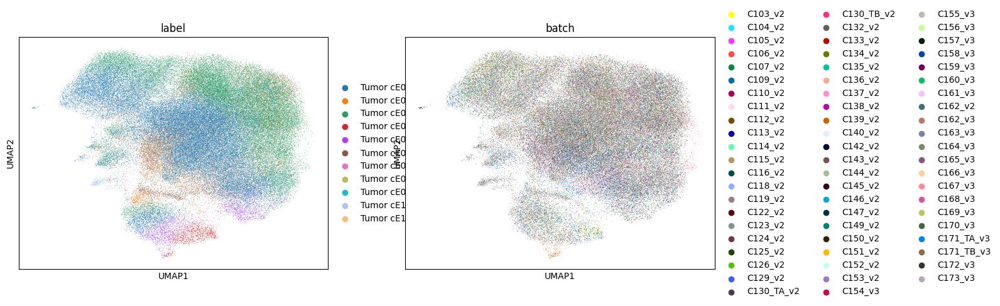

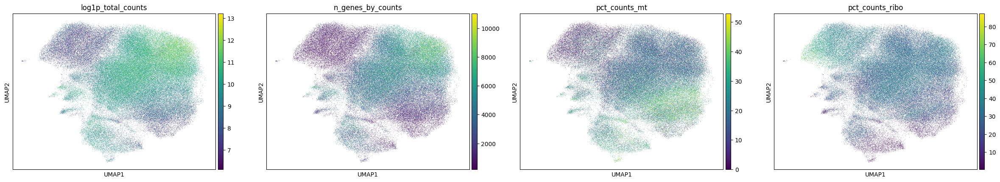

In [35]:
visualizations(adata_donor_chem, scvi_donor_chem)

In [36]:
del adata_donor_chem, scvi_donor_chem

## batch: Donor_sample_chem

In [37]:
adata_batch = adata_tumor.copy()

sc.pp.highly_variable_genes(
    adata_batch,
    n_top_genes=num_hvg,
    subset=True,
    layer="counts",
    flavor="seurat_v3",
    batch_key="batch"
)

In [38]:
if True: 
    scvi_batch = scvi.model.SCVI.load("scvi_log/2026-08-03_09-45-34_elbo_validation/epoch=209-step=80010-elbo_validation=2034.6083984375",
                                     adata=adata_batch)
else: 
    scvi.model.SCVI.setup_anndata(
        adata_batch,
        layer="counts",
        batch_key="batch"
    )

    scvi_batch = scvi.model.SCVI(
        adata_batch,
        # model paras
        n_layers = n_layer,
        n_hidden = n_hidden,
        n_latent = n_latent,
        # VAE paras
        encode_covariates=encode_covariates,
        deeply_inject_covariates=deeply_inject_covariates
    )

    scvi_batch.train(
        batch_size=256,
        early_stopping=True, max_epochs=400,
        callbacks=[
            scvi.train.SaveCheckpoint(
                monitor="elbo_validation", load_best_on_end=True
            )
        ],
        datasplitter_kwargs={"num_workers":3},
        plan_config={"n_epochs_kl_warmup":50},
        trainer_config={"early_stopping_patience":early_stopping_patience}
    )

INFO     File                                                                                                      
         scvi_log/2026-08-03_09-45-34_elbo_validation/epoch=209-step=80010-elbo_validation=2034.6083984375/model.pt
         already downloaded                                                                                        


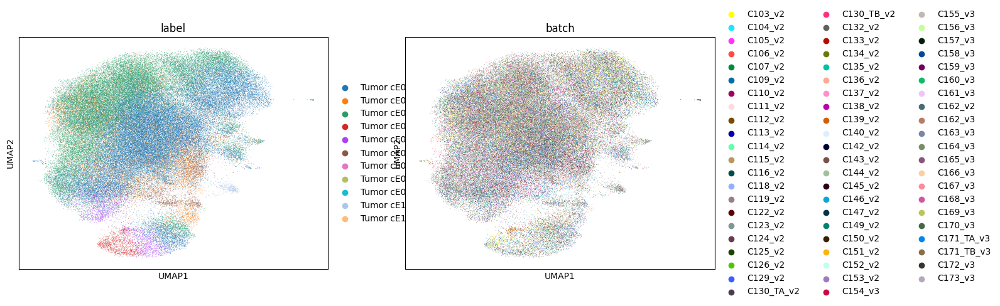

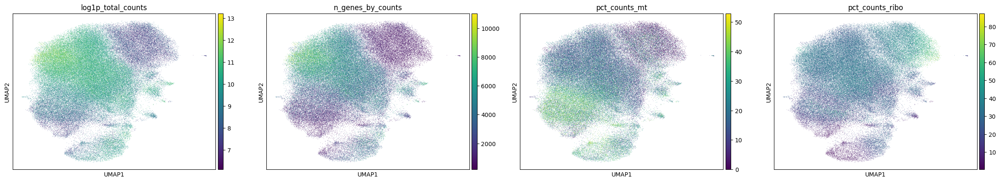

In [39]:
visualizations(adata_batch, scvi_batch)

In [40]:
del adata_batch, scvi_batch

## biosample_id

In [41]:
adata_biosample = adata_tumor.copy()

sc.pp.highly_variable_genes(
    adata_biosample,
    n_top_genes=5000,
    subset=True,
    layer="counts",
    flavor="seurat_v3",
    batch_key="batch" # USING BATCH as biosample cant fit LOESS and lower top_genes still kills the kernel
)

In [42]:
if True: 
    scvi_biosample = scvi.model.SCVI.load("scvi_log/2026-08-03_10-25-58_elbo_validation/epoch=198-step=75819-elbo_validation=2035.80859375",
                                     adata=adata_biosample)
else: 
    scvi.model.SCVI.setup_anndata(
        adata_biosample,
        layer="counts",
        batch_key="biosample_id"
    )

    scvi_biosample = scvi.model.SCVI(
        adata_biosample,
        # model paras
        n_layers = n_layer,
        n_hidden = n_hidden,
        n_latent = n_latent,
        # VAE paras
        encode_covariates=encode_covariates,
        deeply_inject_covariates=deeply_inject_covariates
    )

    scvi_biosample.train(
        batch_size=256,
        early_stopping=True, max_epochs=400,
        callbacks=[
            scvi.train.SaveCheckpoint(
                monitor="elbo_validation", load_best_on_end=True
            )
        ],
        datasplitter_kwargs={"num_workers":3},
        plan_config={"n_epochs_kl_warmup":50},
        trainer_config={"early_stopping_patience":early_stopping_patience}
    )

INFO     File                                                                                                      
         scvi_log/2026-08-03_10-25-58_elbo_validation/epoch=198-step=75819-elbo_validation=2035.80859375/model.pt  
         already downloaded                                                                                        


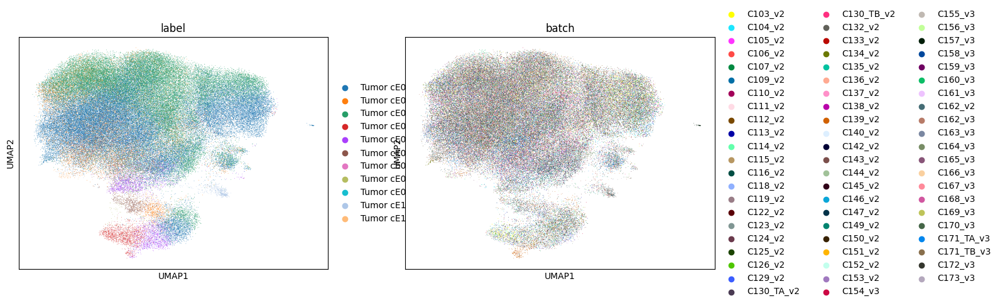

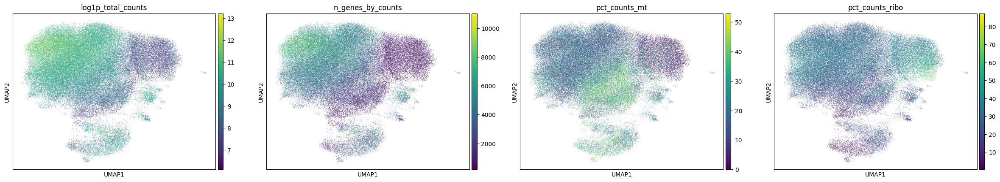

In [43]:
visualizations(adata_biosample, scvi_biosample)

In [34]:
adata_tumor.obs['batch'].value_counts().to_frame().sort_index().style

,count
batch,
C103_v2,4580
C104_v2,1694
C105_v2,1388
C106_v2,1113
C107_v2,2156
C109_v2,1511
C110_v2,790
C111_v2,650
C112_v2,1760


In [35]:
adata_tumor.obs['donor_id'].value_counts().to_frame().sort_index().style

,count
donor_id,
C103,4580
C104,1694
C105,1388
C106,1113
C107,2156
C109,1511
C110,790
C111,650
C112,1760


In [19]:
adata_tumor.obs['biosample_id'].value_counts().to_frame().sort_index().style

,count
biosample_id,
C103_T_1_1_0_c1_v2,4496
C103_T_1_1_3_c1_v2,84
C104_T_1_1_0_c1_v2,1360
C104_T_1_1_3_c1_v2,334
C105_T_1_1_0_c1_v2,1251
C105_T_1_1_3_c1_v2,137
C106_T_1_1_0_c1_v2,832
C106_T_1_1_3_c1_v2,281
C107_T_1_1_0_c1_v2,1594
